In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv("../data/processed/image_metadata.csv")

print(df.shape)
df.head()

(4139, 6)


,room,style,path,width,height,aspect_ratio
0,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,421,0.560570
1,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,472,0.500000
2,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
3,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,183,275,0.665455
4,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,251,201,1.248756


In [17]:
import open_clip

In [2]:
clip_embeddings = torch.load(
    "../data/embeddings/clip_embeddings.pt"
)

resnet_embeddings = torch.load(
    "../data/embeddings/resnet_embeddings.pt"
)

color_embeddings = torch.load(
    "../data/embeddings/color_histograms.pt"
)

print("CLIP:", clip_embeddings.shape)
print("ResNet:", resnet_embeddings.shape)
print("Color:", color_embeddings.shape)

CLIP: torch.Size([4139, 512])
ResNet: torch.Size([4139, 2048])
Color: torch.Size([4139, 96])


In [3]:
query_index = 100
query_path = df.iloc[query_index].path

print(df.iloc[query_index])

room                                                     bathroom
style                                                        boho
path            C:\Users\Khushi Trivedi\visual-retrieval-syste...
width                                                         236
height                                                        354
aspect_ratio                                             0.666667
Name: 100, dtype: object


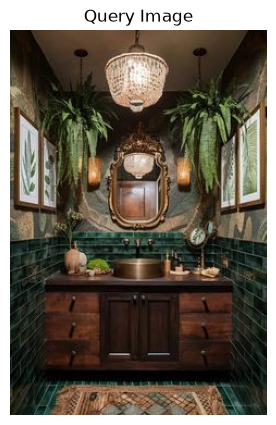

In [4]:
image = Image.open(query_path)

plt.figure(figsize=(4, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Query Image")
plt.show()

In [5]:
def results_to_dataframe(indices, scores, df):
    results = []

    for rank, (index, score) in enumerate(
        zip(indices, scores),
        start=1
    ):
        row = df.iloc[index.item()]

        results.append({
            "rank": rank,
            "room": row.room,
            "style": row.style,
            "similarity": score.item(),
            "path": row.path
        })

    return pd.DataFrame(results)

In [6]:
import numpy as np

def get_color_histogram(image_path, bins=32):
    image = Image.open(image_path).convert("RGB")

    image_array = np.array(image)

    histograms = []

    for channel in range(3):
        histogram, _ = np.histogram(
            image_array[:, :, channel],
            bins=bins,
            range=(0, 256)
        )

        histograms.append(histogram)

    histogram = np.concatenate(histograms)
    histogram = histogram.astype(np.float32)

    histogram = histogram / histogram.sum()

    return histogram

In [7]:
def retrieve_similar_color_images(
    query_path,
    embeddings,
    df,
    top_k=5
):
    query_histogram = torch.tensor(
        get_color_histogram(query_path)
    )

    query_histogram = (
        query_histogram /
        query_histogram.norm()
    )

    similarities = embeddings @ query_histogram

    matches = df.index[
        df["path"] == query_path
    ].tolist()

    if matches:
        similarities[matches[0]] = -1

    top_scores, top_indices = torch.topk(
        similarities,
        k=top_k
    )

    return top_indices, top_scores

In [8]:
color_indices, color_scores = retrieve_similar_color_images(
    query_path,
    color_embeddings,
    df,
    top_k=5
)

color_results = results_to_dataframe(
    color_indices,
    color_scores,
    df
)

color_results

,rank,room,style,similarity,path
0,1,living_room,industrial,0.982280,C:\Users\Khushi Trivedi\visual-retrieval-syste...
1,2,living_room,industrial,0.980583,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2,3,living_room,industrial,0.975543,C:\Users\Khushi Trivedi\visual-retrieval-syste...
3,4,bedroom,industrial,0.975446,C:\Users\Khushi Trivedi\visual-retrieval-syste...
4,5,bedroom,industrial,0.974057,C:\Users\Khushi Trivedi\visual-retrieval-syste...


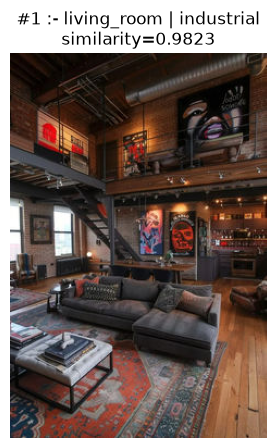

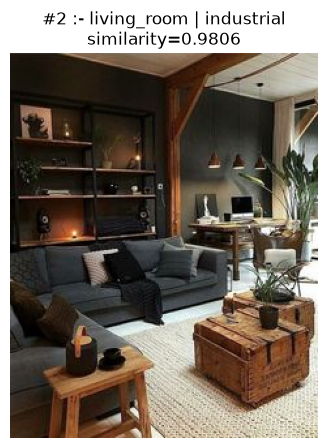

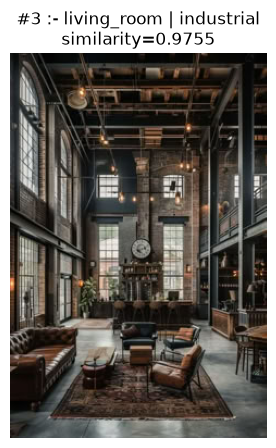

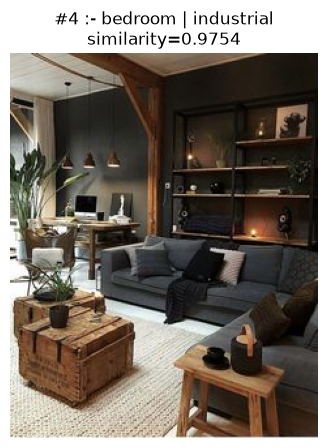

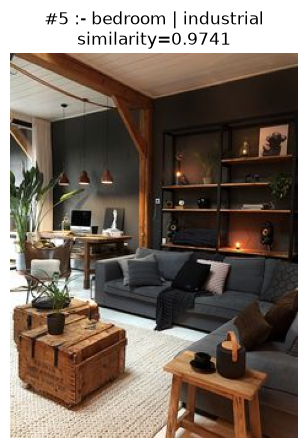

In [10]:
for _, row in color_results.iterrows():
    image = Image.open(row["path"])

    plt.figure(figsize=(4, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f'#{int(row["rank"])} :- '
        f'{row["room"]} | {row["style"]}\n'
        f'similarity={row["similarity"]:.4f}'
    )
    plt.show()

In [11]:
import torch.nn as nn
import torchvision.models as models
from torchvision.models import ResNet50_Weights

weights = ResNet50_Weights.DEFAULT

resnet = models.resnet50(weights=weights)
resnet.fc = nn.Identity()
resnet.eval()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

resnet = resnet.to(device)

resnet_preprocess = weights.transforms()

print(device)

cpu


In [12]:
def get_resnet_embedding(image_path):
    image = Image.open(image_path).convert("RGB")

    image = resnet_preprocess(image)
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = resnet(image)

    embedding = embedding.squeeze(0).cpu()

    embedding = embedding / embedding.norm()

    return embedding

In [13]:
def retrieve_similar_resnet_images(
    query_path,
    embeddings,
    df,
    top_k=5
):
    query_embedding = get_resnet_embedding(query_path)

    similarities = embeddings @ query_embedding

    matches = df.index[
        df["path"] == query_path
    ].tolist()

    if matches:
        similarities[matches[0]] = -1

    top_scores, top_indices = torch.topk(
        similarities,
        k=top_k
    )

    return top_indices, top_scores

In [14]:
resnet_indices, resnet_scores = retrieve_similar_resnet_images(
    query_path,
    resnet_embeddings,
    df,
    top_k=5
)

resnet_results = results_to_dataframe(
    resnet_indices,
    resnet_scores,
    df
)

resnet_results

,rank,room,style,similarity,path
0,1,bathroom,boho,0.685744,C:\Users\Khushi Trivedi\visual-retrieval-syste...
1,2,bathroom,minimalist,0.679097,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2,3,kitchen,boho,0.678338,C:\Users\Khushi Trivedi\visual-retrieval-syste...
3,4,bathroom,industrial,0.671635,C:\Users\Khushi Trivedi\visual-retrieval-syste...
4,5,bathroom,boho,0.670093,C:\Users\Khushi Trivedi\visual-retrieval-syste...


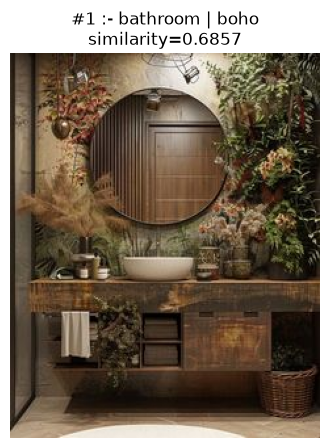

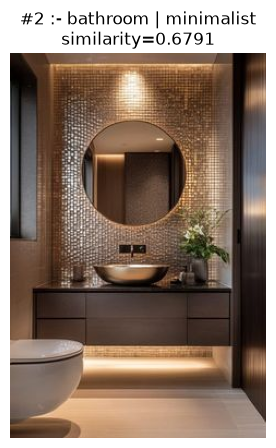

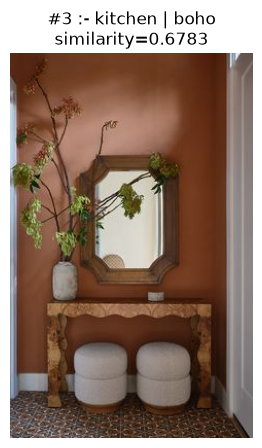

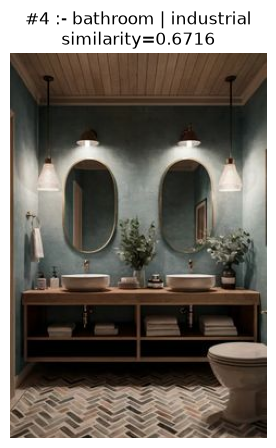

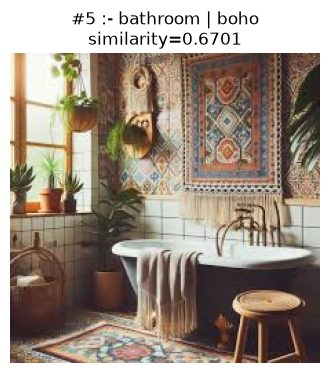

In [16]:
for _, row in resnet_results.iterrows():
    image = Image.open(row["path"])

    plt.figure(figsize=(4, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f'#{int(row["rank"])} :- '
        f'{row["room"]} | {row["style"]}\n'
        f'similarity={row["similarity"]:.4f}'
    )
    plt.show()

In [18]:
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="laion2b_s34b_b79k"
)

In [19]:
def get_clip_embedding(image_path):
    image = Image.open(image_path).convert("RGB")
    
    image = preprocess(image).unsqueeze(0)

    with torch.no_grad():
        embedding = model.encode_image(image)

    embedding = embedding / embedding.norm(dim=-1, keepdim=True)

    return embedding.squeeze(0)

In [20]:
def retrieve_similar_clip_images(
    query_path,
    embeddings,
    df,
    top_k=5
):
    query_embedding = get_clip_embedding(query_path)

    similarities = embeddings @ query_embedding

    matches = df.index[
        df["path"] == query_path
    ].tolist()

    if matches:
        similarities[matches[0]] = -1

    top_scores, top_indices = torch.topk(
        similarities,
        k=top_k
    )

    return top_indices, top_scores

In [21]:
clip_indices, clip_scores = retrieve_similar_clip_images(
    query_path,
    clip_embeddings,
    df,
    top_k=5
)

clip_results = results_to_dataframe(
    clip_indices,
    clip_scores,
    df
)

clip_results

,rank,room,style,similarity,path
0,1,bathroom,boho,0.847534,C:\Users\Khushi Trivedi\visual-retrieval-syste...
1,2,bathroom,boho,0.832629,C:\Users\Khushi Trivedi\visual-retrieval-syste...
2,3,bathroom,boho,0.828794,C:\Users\Khushi Trivedi\visual-retrieval-syste...
3,4,bathroom,boho,0.827317,C:\Users\Khushi Trivedi\visual-retrieval-syste...
4,5,bathroom,modern,0.821106,C:\Users\Khushi Trivedi\visual-retrieval-syste...


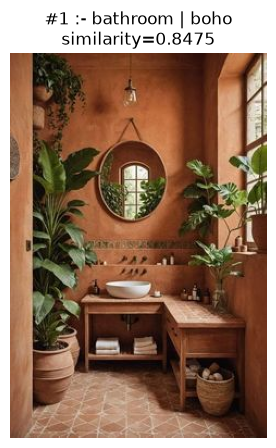

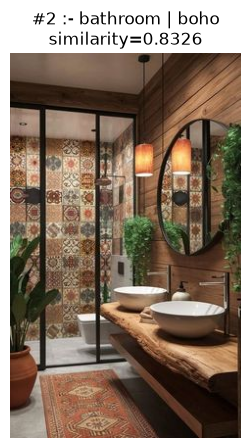

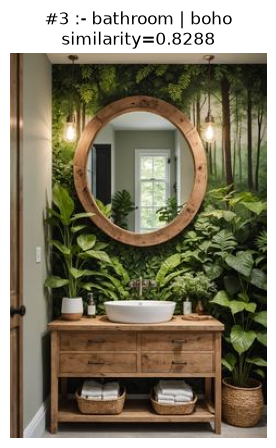

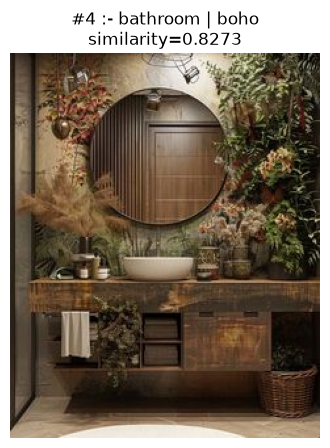

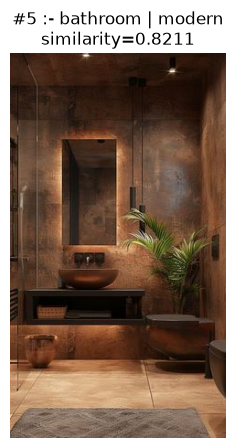

In [23]:
for _, row in clip_results.iterrows():
    image = Image.open(row["path"])

    plt.figure(figsize=(4, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f'#{int(row["rank"])} :- '
        f'{row["room"]} | {row["style"]}\n'
        f'similarity={row["similarity"]:.4f}'
    )
    plt.show()

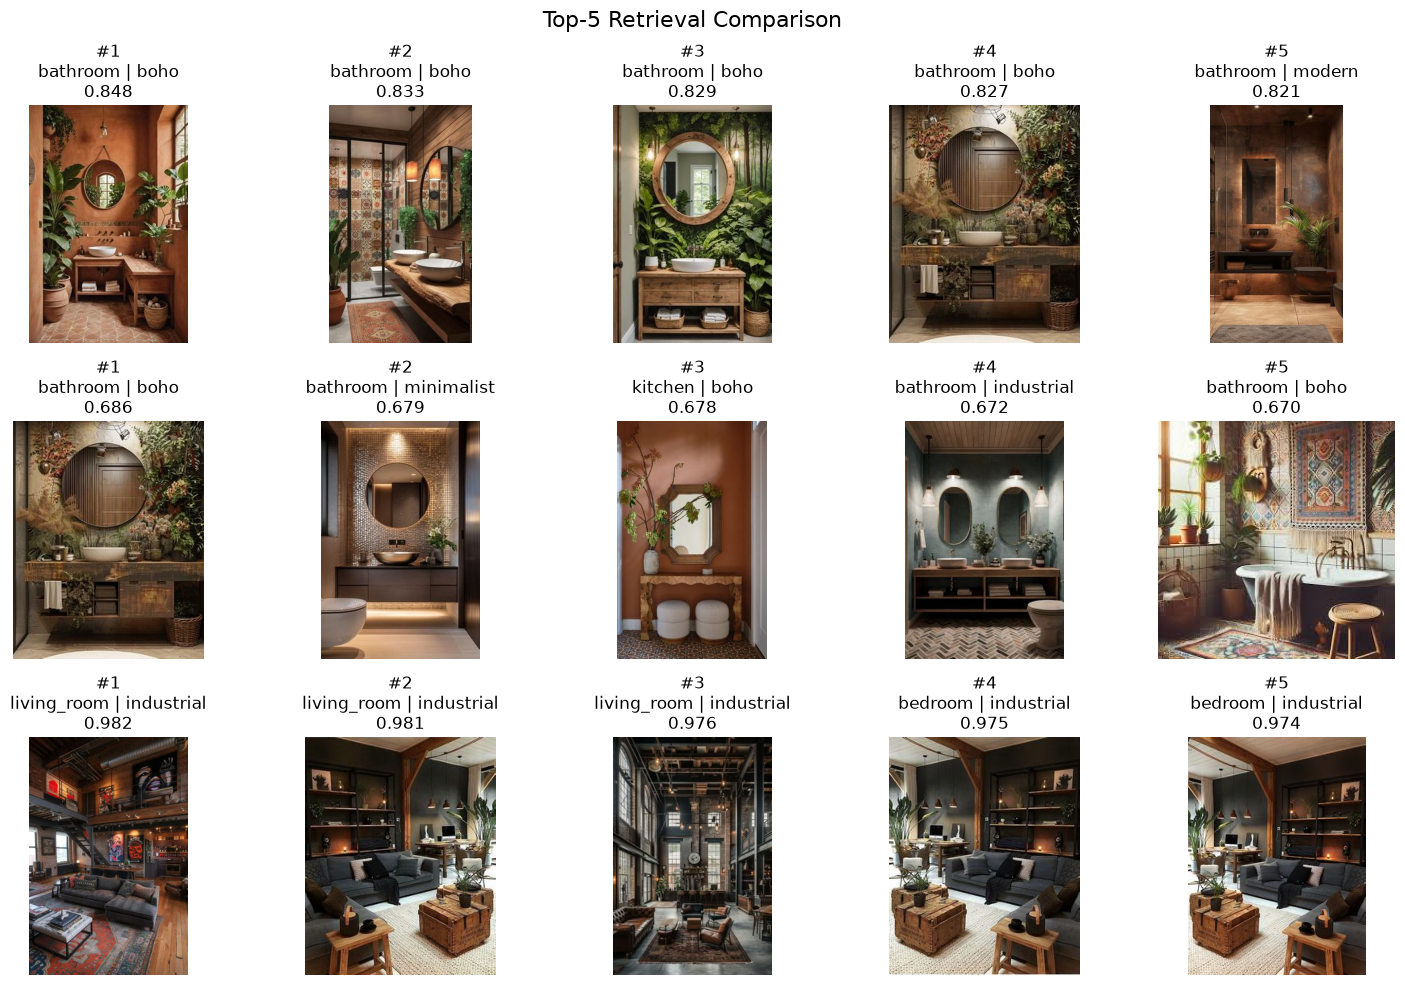

In [24]:
fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 10)
)

results_list = [
    ("CLIP", clip_results),
    ("ResNet", resnet_results),
    ("Color Histogram", color_results)
]

for row_idx, (model_name, results) in enumerate(results_list):

    for col_idx, (_, row) in enumerate(results.iterrows()):

        image = Image.open(row["path"])

        axes[row_idx, col_idx].imshow(image)
        axes[row_idx, col_idx].axis("off")

        axes[row_idx, col_idx].set_title(
            f"#{int(row['rank'])}\n"
            f"{row['room']} | {row['style']}\n"
            f"{row['similarity']:.3f}"
        )

    axes[row_idx, 0].set_ylabel(
        model_name,
        fontsize=14
    )

plt.suptitle(
    "Top-5 Retrieval Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()